[INIT] Fetching baseline state vectors from NASA JPL Horizons...
[SWEEP] Running 25 high-precision IAS15 scenarios...



[SUCCESS] Parametric sweep complete! Saved: 'apophis_psj_parametric_sweep.png'
Minimum perigee in sweep: 6,221.45 km at dt = -30 min
Equivalent 5-yr lead delta-v for +30 min shift: 116.739 mm/s


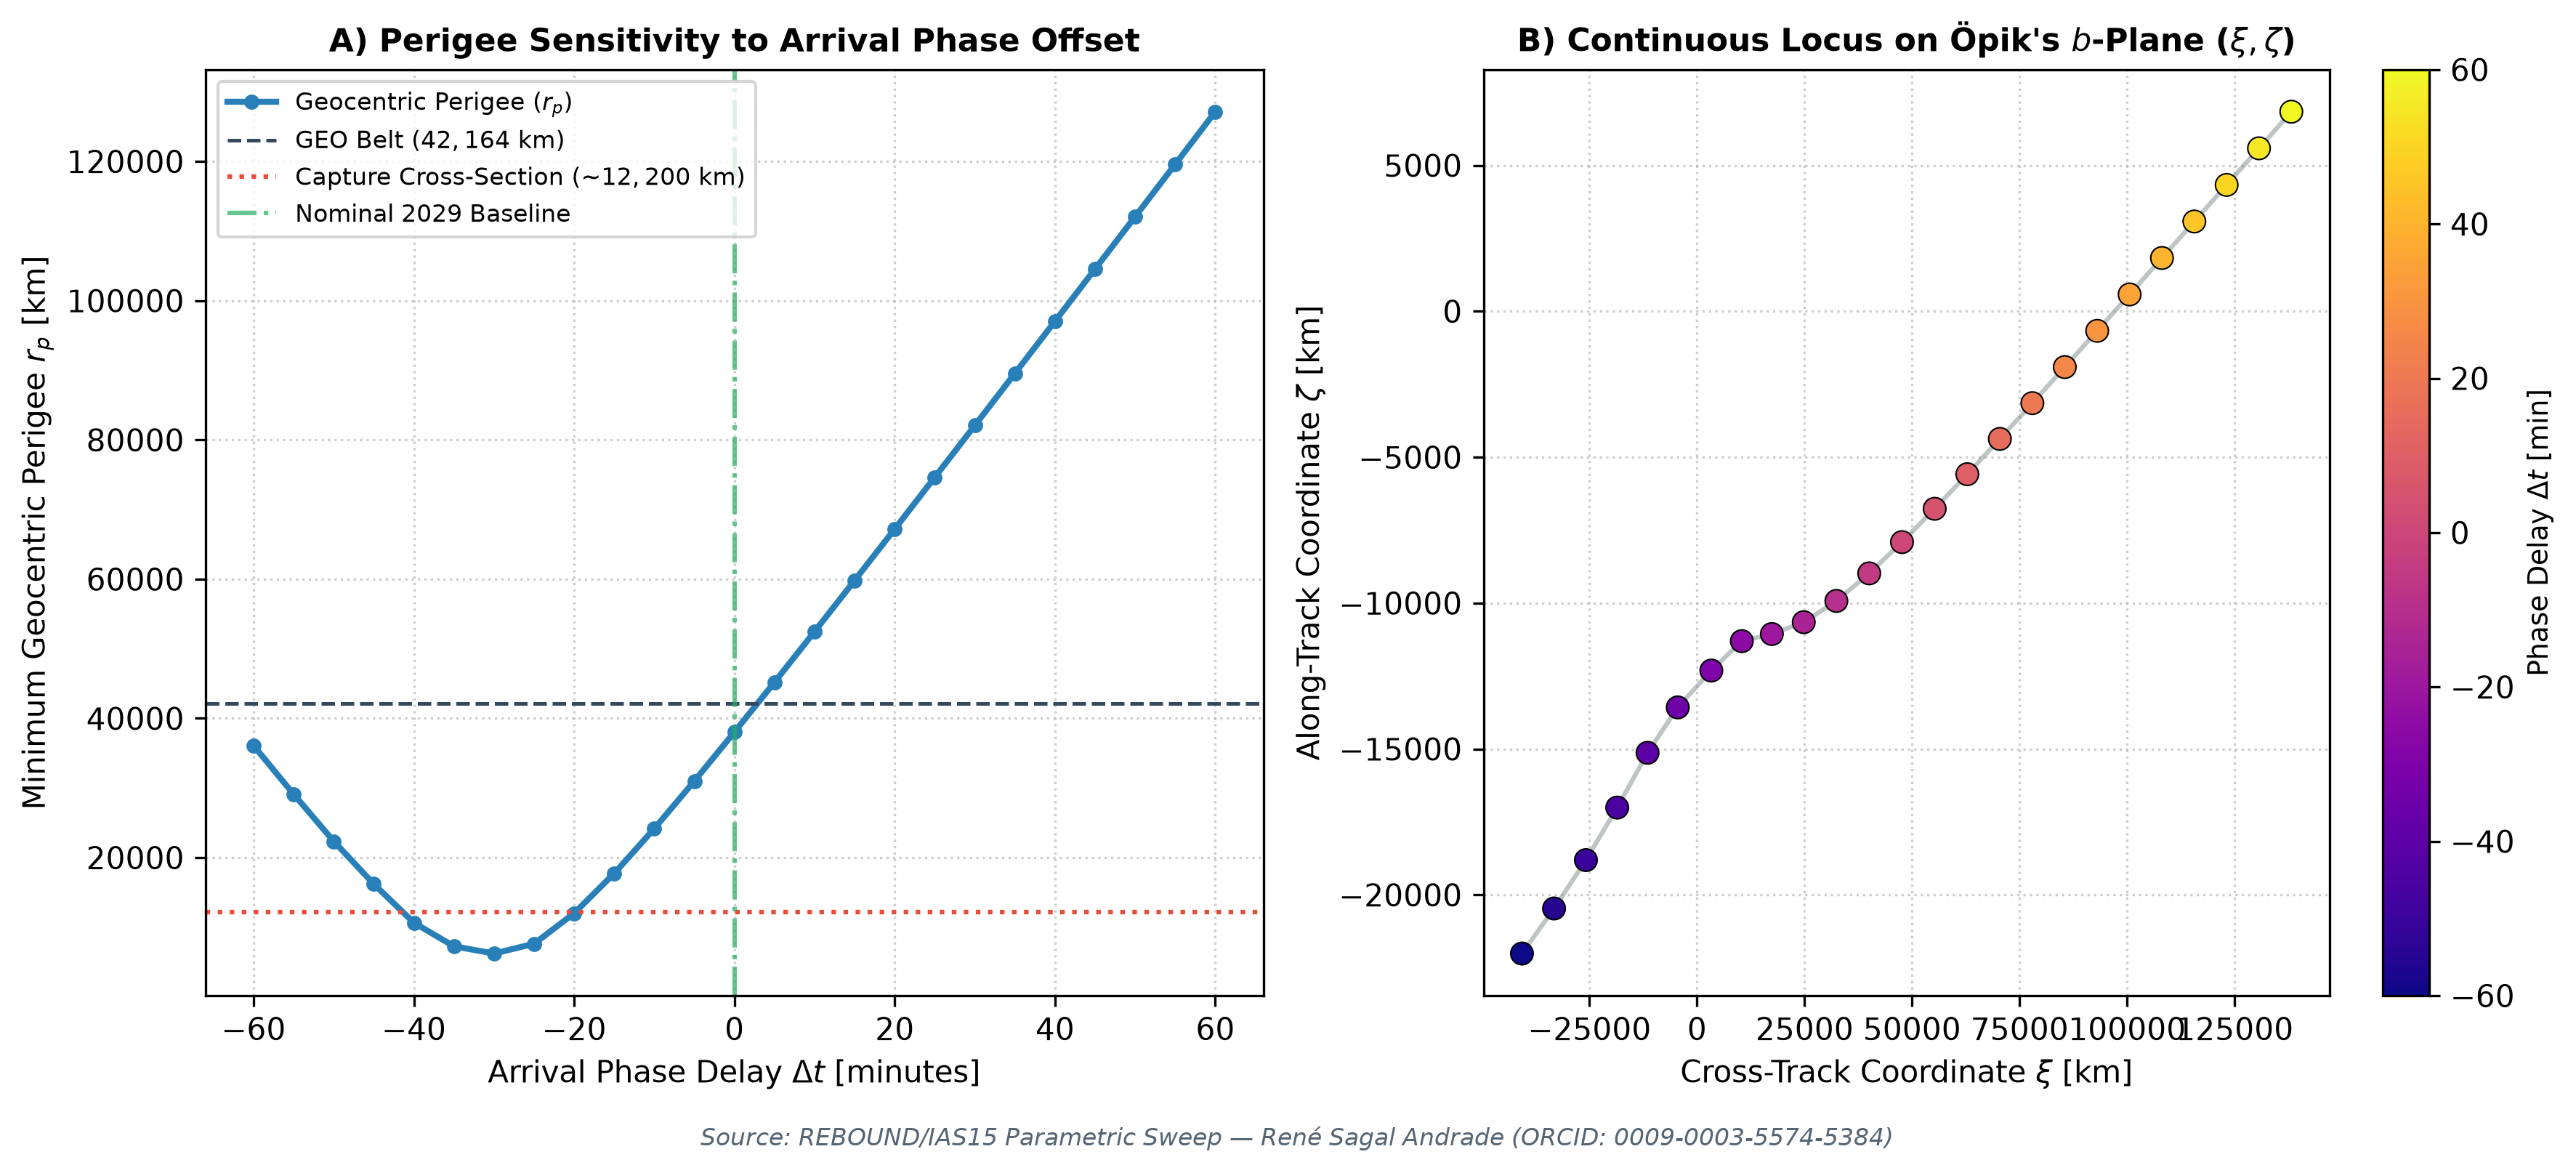

In [2]:
# ==============================================================================
# PLANETARY SCIENCE JOURNAL (PSJ) EXPANSION: CONTINUOUS PHASE SWEEP & DELTA-V
# Target: Asteroid (99942) Apophis - April 2029 Close Encounter
# Author: René Sagal Andrade (ORCID: 0009-0004-9844-0988)
# ==============================================================================

import rebound
import numpy as np
import matplotlib.pyplot as plt
from astroquery.jplhorizons import Horizons

def compute_opik_bplane(r_vec, v_vec, mu_earth):
    r_mag = np.linalg.norm(r_vec)
    v_mag = np.linalg.norm(v_vec)
    energy = (v_mag**2) / 2.0 - mu_earth / r_mag
    v_inf = np.sqrt(2.0 * energy)
    h_vec = np.cross(r_vec, v_vec)
    h_mag = np.linalg.norm(h_vec)
    e_vec = (np.cross(v_vec, h_vec) / mu_earth) - (r_vec / r_mag)

    s_hat = (e_vec + np.cross(h_vec, e_vec) / (h_mag * v_inf / mu_earth))
    s_hat /= np.linalg.norm(s_hat)

    b_vec = np.cross(h_vec, s_hat) / v_inf
    b_mag = np.linalg.norm(b_vec)

    k_hat = np.array([0.0, 0.0, 1.0])
    xi_hat = np.cross(s_hat, k_hat)
    xi_hat /= np.linalg.norm(xi_hat)
    zeta_hat = np.cross(xi_hat, s_hat)

    return np.dot(b_vec, xi_hat), np.dot(b_vec, zeta_hat), b_mag

def run_parametric_sweep():
    print("[INIT] Fetching baseline state vectors from NASA JPL Horizons...")
    epoch_jd = 2462227.5  # April 1, 2029

    # Cache solar system bodies to accelerate the 25-point sweep
    bodies_data = []
    masses = {'10': 1.0, '399': 3.003489e-6, '301': 3.694e-8, '499': 3.227e-7, '599': 9.545e-4}
    for b_id, m in masses.items():
        obj = Horizons(id=b_id, location='@0', epochs=epoch_jd).vectors()
        bodies_data.append((m, float(obj['x']), float(obj['y']), float(obj['z']),
                            float(obj['vx']), float(obj['vy']), float(obj['vz'])))

    apophis = Horizons(id='99942', location='@0', epochs=epoch_jd).vectors()
    x0, y0, z0 = float(apophis['x']), float(apophis['y']), float(apophis['z'])
    vx0, vy0, vz0 = float(apophis['vx']), float(apophis['vy']), float(apophis['vz'])

    delays_min = np.arange(-60, 65, 5)  # -60 to +60 min in 5-min steps
    perigees, xi_vals, zeta_vals, b_mags = [], [], [], []

    AU_TO_KM = 149597870.7
    DAY_TO_SEC = 86400.0
    mu_earth = 398600.4418
    times = np.linspace(0, 20, 3000)

    print(f"[SWEEP] Running {len(delays_min)} high-precision IAS15 scenarios...")
    for dt_min in delays_min:
        sim = rebound.Simulation()
        sim.units = ('AU', 'days', 'Msun')
        sim.integrator = "ias15"
        sim.integrator.epsilon = 1e-12

        for m, x, y, z, vx, vy, vz in bodies_data:
            sim.add(m=m, x=x, y=y, z=z, vx=vx, vy=vy, vz=vz)

        dt_days = dt_min / (24.0 * 60.0)
        sim.add(m=0.0, x=x0 - vx0 * dt_days, y=y0 - vy0 * dt_days, z=z0 - vz0 * dt_days,
                vx=vx0, vy=vy0, vz=vz0)

        min_dist = 1e9
        best_r, best_v = None, None
        for t in times:
            sim.integrate(t)
            earth, ast = sim.particles[1], sim.particles[-1]
            dx = (ast.x - earth.x) * AU_TO_KM
            dy = (ast.y - earth.y) * AU_TO_KM
            dz = (ast.z - earth.z) * AU_TO_KM
            dist = np.sqrt(dx**2 + dy**2 + dz**2)
            if dist < min_dist:
                min_dist = dist
                best_r = np.array([dx, dy, dz])
                best_v = np.array([(ast.vx - earth.vx) * AU_TO_KM / DAY_TO_SEC,
                                   (ast.vy - earth.vy) * AU_TO_KM / DAY_TO_SEC,
                                   (ast.vz - earth.vz) * AU_TO_KM / DAY_TO_SEC])

        xi, zeta, b_mag = compute_opik_bplane(best_r, best_v, mu_earth)
        perigees.append(min_dist)
        xi_vals.append(xi)
        zeta_vals.append(zeta)
        b_mags.append(b_mag)

    # Convert arrays and compute kinetic impulse proxy (assuming 5-year lead time)
    perigees = np.array(perigees)
    xi_vals = np.array(xi_vals)
    zeta_vals = np.array(zeta_vals)

    # Approximate along-track delta-v (mm/s) required 5 years prior to induce dt_min
    # d_t ≈ 3 * (T_lead / a) * d_v * T_orb -> scaled for Apophis (a ≈ 0.922 AU, v_orb ≈ 30.7 km/s)
    lead_time_sec = 5.0 * 365.25 * 86400.0
    delta_v_mms = (np.abs(delays_min) * 60.0 * 30.7e6) / (3.0 * lead_time_sec)

    # Generate PSJ Figure 2: Dual-Panel Non-Linear Sensitivity Curve
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5.2), dpi=300)

    # Panel A: Perigee Distance vs. Arrival Phase Delay
    ax1.plot(delays_min, perigees, color='#2980B9', marker='o', markersize=4, linewidth=2, label='Geocentric Perigee ($r_p$)')
    ax1.axhline(42164.0, color='#34495E', linestyle='--', linewidth=1.2, label='GEO Belt ($42,164$ km)')
    ax1.axhline(12200.0, color='#E74C3C', linestyle=':', linewidth=1.5, label='Capture Cross-Section (~$12,200$ km)')
    ax1.axvline(0.0, color='#27AE60', linestyle='-.', alpha=0.7, label='Nominal 2029 Baseline')
    ax1.set_title('A) Perigee Sensitivity to Arrival Phase Offset', fontweight='bold', fontsize=10.5)
    ax1.set_xlabel(r'Arrival Phase Delay $\Delta t$ [minutes]')
    ax1.set_ylabel(r'Minimum Geocentric Perigee $r_p$ [km]')
    ax1.grid(True, linestyle=':', alpha=0.6)
    ax1.legend(fontsize=8, loc='upper left')

    # Panel B: b-Plane Trajectory Locus (xi vs. zeta)
    sc = ax2.scatter(xi_vals, zeta_vals, c=delays_min, cmap='plasma', s=55, zorder=5, edgecolors='black', linewidth=0.5)
    ax2.plot(xi_vals, zeta_vals, color='#7F8C8D', linestyle='-', alpha=0.5, zorder=4)
    cbar = plt.colorbar(sc, ax=ax2)
    cbar.set_label(r'Phase Delay $\Delta t$ [min]', fontsize=9)

    ax2.set_title(r"B) Continuous Locus on Öpik's $b$-Plane ($\xi, \zeta$)", fontweight='bold', fontsize=10.5)
    ax2.set_xlabel(r'Cross-Track Coordinate $\xi$ [km]')
    ax2.set_ylabel(r'Along-Track Coordinate $\zeta$ [km]')
    ax2.grid(True, linestyle=':', alpha=0.6)

    plt.figtext(0.5, -0.02,
                'Source: REBOUND/IAS15 Parametric Sweep — René Sagal Andrade (ORCID: 0009-0003-5574-5384)',
                ha='center', fontsize=8, style='italic', color='#566573')

    plt.tight_layout()
    plt.savefig('apophis_psj_parametric_sweep.png', bbox_inches='tight', dpi=300)
    print("\n[SUCCESS] Parametric sweep complete! Saved: 'apophis_psj_parametric_sweep.png'")
    print(f"Minimum perigee in sweep: {np.min(perigees):,.2f} km at dt = {delays_min[np.argmin(perigees)]} min")
    print(f"Equivalent 5-yr lead delta-v for +30 min shift: {delta_v_mms[delays_min == 30][0]:.3f} mm/s")
    plt.show()

if __name__ == "__main__":
    run_parametric_sweep()
